In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

In [3]:
batch_size = 2048
device = torch.device('cpu')
train_loader = torch. utils.data.DataLoader(datasets.MNIST('data', train=True, download=True, transform=transforms.Compose([transforms.ToTensor(),])), batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(datasets.MNIST('data', train=False, transform=transforms.Compose([transforms. ToTensor(),])), batch_size=batch_size, shuffle=True)

print(train_loader.dataset.data.shape)

100.0%
100.0%
100.0%
100.0%

torch.Size([60000, 28, 28])


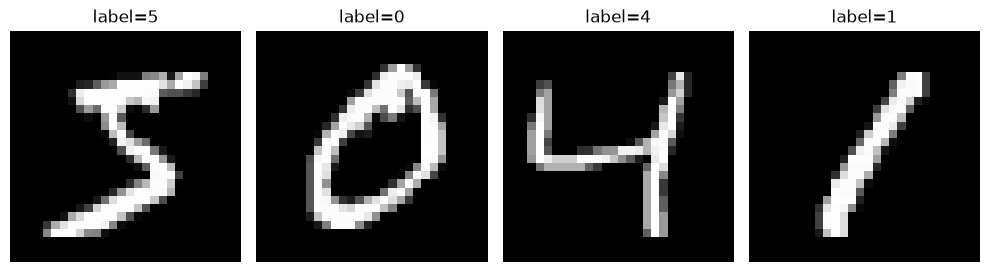

In [9]:
images = train_loader.dataset.data[:4]  
labels = train_loader.dataset.targets[:4]  

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i in range(4):
    axes[i].imshow(images[i], cmap='gray')
    axes[i].set_title(f'label={labels[i].item()}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [5]:
class mlp(nn.Module):
    def __init__(self):
        super(mlp,self).__init__()
        self.l1=nn.Linear(784,128)
        self.l2=nn.Linear(128,10)

    def forward(self,x):
        a1 = self.l1(x)
        x1 = F.relu(a1)
        a2 = self.l2(x1)
        return a2

model = mlp().to(device)
optimizer = optim.SGD(model.parameters(),lr=0.01)
print(model)

mlp(
  (l1): Linear(in_features=784, out_features=128, bias=True)
  (l2): Linear(in_features=128, out_features=10, bias=True)
)


In [10]:
epochs = 50
for epoch in range(epochs):
    model.train()
    for batch_idx, (x,y) in enumerate(train_loader):
        x, y = x. view(x. shape[0],-1).to(device), y.to(device)
        optimizer.zero_grad()
        output = model(x)
        loss = F.cross_entropy(output, y)
        loss.backward()
        optimizer.step()

    model.eval()
    correct = 0
    test_loss = 0
    with torch.no_grad():
        for batch_idx, (x,y) in enumerate(test_loader):
            x,y=x.view(x.shape[0],-1).to(device), y.to(device)
            output = model(x)
            test_loss += F.cross_entropy(output, y)
            pred = output.max(1, keepdim=True)[1]
            correct += pred.eq(y.view_as(pred)).sum().item()

    test_loss = test_loss/(batch_idx+1)
    acc = correct/len(test_loader.dataset)
    print('epoch:{}, loss:{:.4f}, acc:{:.4f}'.format(epoch, test_loss, acc))

epoch:0, loss:0.5692, acc:0.8681
epoch:1, loss:0.5589, acc:0.8697
epoch:2, loss:0.5494, acc:0.8710
epoch:3, loss:0.5392, acc:0.8728
epoch:4, loss:0.5295, acc:0.8736
epoch:5, loss:0.5219, acc:0.8751
epoch:6, loss:0.5146, acc:0.8756
epoch:7, loss:0.5060, acc:0.8770
epoch:8, loss:0.4990, acc:0.8782
epoch:9, loss:0.4922, acc:0.8796
epoch:10, loss:0.4855, acc:0.8798
epoch:11, loss:0.4803, acc:0.8803
epoch:12, loss:0.4746, acc:0.8818
epoch:13, loss:0.4691, acc:0.8823
epoch:14, loss:0.4644, acc:0.8835
epoch:15, loss:0.4581, acc:0.8848
epoch:16, loss:0.4536, acc:0.8853
epoch:17, loss:0.4491, acc:0.8851
epoch:18, loss:0.4448, acc:0.8857
epoch:19, loss:0.4414, acc:0.8873
epoch:20, loss:0.4377, acc:0.8875
epoch:21, loss:0.4337, acc:0.8881
epoch:22, loss:0.4299, acc:0.8890
epoch:23, loss:0.4266, acc:0.8897
epoch:24, loss:0.4237, acc:0.8904
epoch:25, loss:0.4204, acc:0.8910
epoch:26, loss:0.4160, acc:0.8921
epoch:27, loss:0.4140, acc:0.8925
epoch:28, loss:0.4111, acc:0.8927
epoch:29, loss:0.4077, a